# AquaTrace: Which medicine can our 7 sensors "see"? (real data)

**Data:** 28,046 real river samples from the **US Water Quality Portal** (USGS + EPA): 5,983 river sites, 51 states, 1999–2025.
Each row = one river site on one day, with **field sensor readings** (pH, DO, conductivity, temperature, turbidity; ORP and UV254 where available) **and** **lab results** for 7 medicines.

**The question (核心问题):** for each medicine, do the sensor readings tell us when it is **high**?

| Step | What happens |
|---|---|
| 1 | Load + clean (remove impossible values) |
| 2 | Define "high" = above a fixed level (the median of all detected values) |
| 3 | Relate each of the 7 properties to "high vs low" |
| 4 | Within one river over time: does the medicine move with the sensors? |
| 5 | Model per medicine, tested on rivers it never saw |
| 6 | Harder test: whole states it never saw |
| 7 | What this means for Penang |

> ⚠️ **Honest note:** this is US river data, not Penang. It shows **which sensor relationships are real**. The final Penang model still needs local samples.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings; warnings.filterwarnings('ignore')
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, r2_score
from sklearn.inspection import permutation_importance

# On Colab: upload wqp_paired_streams.csv first
# from google.colab import files; files.upload()
df = pd.read_csv('wqp_paired_streams.csv', low_memory=False)
print(df.shape, '| sites:', df.site.nunique(), '| states:', df.state.nunique())
df.head(3)

(28046, 27) | sites: 5983 | states: 51


,site,date,org,lat,lon,state,ph,do,sc,temp,...,Diclofenac_ngL,Diclofenac_lim_ngL,Atenolol_ngL,Atenolol_lim_ngL,Ketoprofen_ngL,Ketoprofen_lim_ngL,Sulfamethoxazole_ngL,Sulfamethoxazole_lim_ngL,Caffeine_ngL,Caffeine_lim_ngL
0,USGS-14204530,2002-07-25,USGS-OR,45.510670,-123.115663,41.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.1,NaN,8.0
1,USGS-390127094365800,2002-11-07,USGS-KS,39.024167,-94.616111,20.0,7.50,NaN,392.0,7.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.0,400.0,NaN
2,USGS-390127094365800,2003-07-15,USGS-KS,39.024167,-94.616111,20.0,7.95,NaN,499.0,27.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.0,39.0,NaN


## Step 1: Clean (清洗数据)
Remove physically impossible readings (e.g. pH 2.8, DO 100 mg/L, water at 61 °C). These are typing or unit errors.

Already done while building the file:
- Quality-control samples (blanks, spikes) removed
- Units converted to **ng/L**
- A result only counts as **detected** if it is above its lab's detection limit and not flagged "U" (some agencies store the limit itself as the value, a trap)

In [2]:
rng = {'ph':(3,11),'do':(0,20),'sc':(1,60000),'temp':(-1,40),'turb':(0,4000),'orp':(-500,900),'uv254':(0,5)}
for c,(lo,hi) in rng.items():
    df.loc[(df[c]<lo)|(df[c]>hi), c] = np.nan
t = pd.to_datetime(df.date)
df['log_sc'], df['log_turb'] = np.log10(df.sc), np.log10(df.turb+0.1)
df['doy_sin'], df['doy_cos'] = np.sin(2*np.pi*t.dt.dayofyear/365.25), np.cos(2*np.pi*t.dt.dayofyear/365.25)
SENS = ['ph','do','sc','temp','turb','orp','uv254']
NAME = {'ph':'pH','do':'Dissolved oxygen','sc':'Conductivity','temp':'Temperature','turb':'Turbidity','orp':'ORP','uv254':'UV254'}
print('Rows with each sensor:'); print(df[SENS].notna().sum().rename(NAME).to_string())
MEDS = ['Carbamazepine','Acetaminophen','Diclofenac','Atenolol','Ketoprofen','Sulfamethoxazole','Caffeine']
print('\nDetected values per medicine:'); print(pd.Series({m: df[m+'_ngL'].notna().sum() for m in MEDS}).to_string())

Rows with each sensor:
pH                  23700
Dissolved oxygen    13991
Conductivity        20166
Temperature         23179
Turbidity           14015
ORP                    55
UV254                 523

Detected values per medicine:
Carbamazepine       2048
Acetaminophen        872
Diclofenac            62
Atenolol             190
Ketoprofen             3
Sulfamethoxazole    1536
Caffeine            4453


**Reading it:** ORP (55 rows) and UV254 (523) are rare in public data, so the models use the **5 common sensors + season**. Diclofenac (62 detections) and ketoprofen (3) are too rare in US rivers to model; Penang levels are far higher, so local data will matter most for them.

## Step 2: Define "high" (定义"高")
Labs have different detection limits, so "detected or not" partly measures the **lab**, not the water. Fairer: **is it above a fixed level T?** A non-detect counts as "below" only if its lab could see down to T.

In [3]:
FEAT = ['ph','do','log_sc','temp','log_turb','doy_sin','doy_cos']
FN = {'ph':'pH','do':'Dissolved oxygen','log_sc':'Conductivity','temp':'Temperature','log_turb':'Turbidity','doy_sin':'Season','doy_cos':'Season'}
def make_target(m):
    v, lim = m+'_ngL', m+'_lim_ngL'
    T = float(np.nanmedian(df[v]))
    d0 = df[df[v].notna() | df[lim].notna()].copy()
    hi, lo = d0[v] >= T, (d0[v] < T) | (d0[v].isna() & (d0[lim] <= T))
    d = d0[hi | lo].copy(); d['y'] = (d[v] >= T).astype(int)
    d = d[d[['ph','do','sc','temp','turb']].notna().sum(axis=1) >= 2]
    return d, T
DATA = {m: make_target(m) for m in MEDS}
pd.DataFrame({m: {'level T (ng/L)': round(T,1), 'usable rows': len(d), 'above T': int(d.y.sum()), 'sites': d.site.nunique()} for m,(d,T) in DATA.items()}).T

,level T (ng/L),usable rows,above T,sites
Carbamazepine,11.9,13054.0,890.0,3090.0
Acetaminophen,42.0,12485.0,398.0,2859.0
Diclofenac,22.8,1512.0,10.0,112.0
Atenolol,30.8,1426.0,82.0,599.0
Ketoprofen,40.6,72.0,0.0,14.0
Sulfamethoxazole,38.4,4193.0,669.0,1069.0
Caffeine,100.0,11360.0,1724.0,2526.0


## Step 3: Each of the 7 properties vs "high" (7个指标 vs 高浓度)
Number = **median when HIGH ÷ median when LOW**. Above 1 = higher when the medicine is high; below 1 = lower.

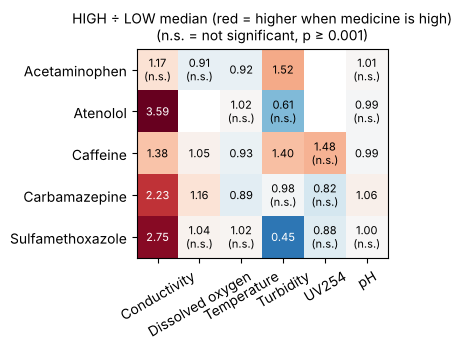

In [4]:
rel = {}; pv = {}
for m,(d,T) in DATA.items():
    for c in SENS:
        a, b = d.loc[d.y==1, c].dropna(), d.loc[d.y==0, c].dropna()
        if len(a) >= 20 and len(b) >= 20:
            rel[(m, NAME[c])] = a.median()/b.median(); pv[(m, NAME[c])] = mannwhitneyu(a,b).pvalue
R = pd.Series(rel).unstack(); P = pd.Series(pv).unstack()
fig, ax = plt.subplots(figsize=(9,3.6))
im = ax.imshow(np.log2(R.values.astype(float)), cmap='RdBu_r', vmin=-1.6, vmax=1.6)
ax.set_xticks(range(R.shape[1]), R.columns, rotation=30); ax.set_yticks(range(R.shape[0]), R.index)
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        val, p = R.iat[i,j], P.iat[i,j]
        if pd.notna(val): ax.text(j, i, f"{val:.2f}" + ('' if p < 0.001 else '\n(n.s.)'), ha='center', va='center', fontsize=8, color='white' if abs(np.log2(val)) > 1 else 'black')
ax.set_title('HIGH ÷ LOW median (red = higher when medicine is high)\n(n.s. = not significant, p ≥ 0.001)', fontsize=10); plt.tight_layout(); plt.show()

**Reading it:** **Conductivity** is the standout. When atenolol is high, conductivity is about **3.6×** higher; sulfamethoxazole about **2.8×**, carbamazepine about **2.2×**. Treated sewage is salty (salts from food, urine, detergents), so conductivity rises where sewage makes up more of the river.

**Turbidity splits the medicines into two groups (浑浊度把药分成两类):**
- **Paracetamol and caffeine are HIGHER when water is muddy** (1.5× and 1.4×). Both are removed well by treatment plants, so seeing them means **raw sewage**. Heavy rain can make sewers overflow into rivers.
- **Sulfamethoxazole and atenolol are LOWER when muddy** (0.45×, 0.61×). They pass through treatment, so rain just **dilutes** them.

👉 Paracetamol and caffeine = **raw-sewage alarm**; carbamazepine and sulfamethoxazole = **treated-effluent share**.

## Step 4: Within one river over time (同一条河的变化) ⭐
This is closest to the boat use case: **same place, different days**. For every site with ≥ 8 detections, correlate sensor vs medicine (Spearman ρ), then take the median across sites.

In [5]:
W = {}
for m in MEDS:
    v = m+'_ngL'; det = df[df[v].notna()]
    for c in ['ph','do','sc','temp','turb']:
        rh = [spearmanr(g[c], g[v])[0] for s,g in det[[v,c,'site']].dropna().groupby('site') if len(g) >= 8 and g[c].nunique() > 2 and g[v].nunique() > 2]
        rh = [r for r in rh if not np.isnan(r)]
        if len(rh) >= 10: W[(m, NAME[c])] = (np.median(rh), len(rh))
Wt = pd.DataFrame({k: {'median rho': round(v[0],2), 'sites': v[1]} for k,v in W.items()}).T
Wt

median rho  sites
Carbamazepine    pH                      0.07   46.0
                 Dissolved oxygen        0.10   35.0
                 Conductivity            0.50   35.0
                 Temperature            -0.21   44.0
                 Turbidity              -0.38   25.0
Sulfamethoxazole pH                     -0.23   59.0
                 Dissolved oxygen        0.28   48.0
                 Conductivity            0.66   11.0
                 Temperature            -0.53   57.0
                 Turbidity              -0.70   47.0
Caffeine         pH                     -0.13  127.0
                 Dissolved oxygen        0.03   58.0
                 Conductivity            0.01   73.0
                 Temperature            -0.22  118.0
                 Turbidity              -0.11   84.0

**Reading it: the dilution story (稀释效应)**
- **Conductivity ↑ → medicine ↑** (carbamazepine ρ ≈ +0.50, sulfamethoxazole ≈ +0.66)
- **Turbidity ↑ → medicine ↓** (sulfamethoxazole ≈ −0.70, carbamazepine ≈ −0.38)
- **Temperature ↑ → medicine ↓** (sulfamethoxazole ≈ −0.53; warm water and sunlight break medicines down faster)

**Example:** After heavy rain the river is **muddy** (turbidity up) but the sewage is **diluted** (medicine down, conductivity down). In dry weather the river is **mostly effluent** (conductivity up, medicine up).

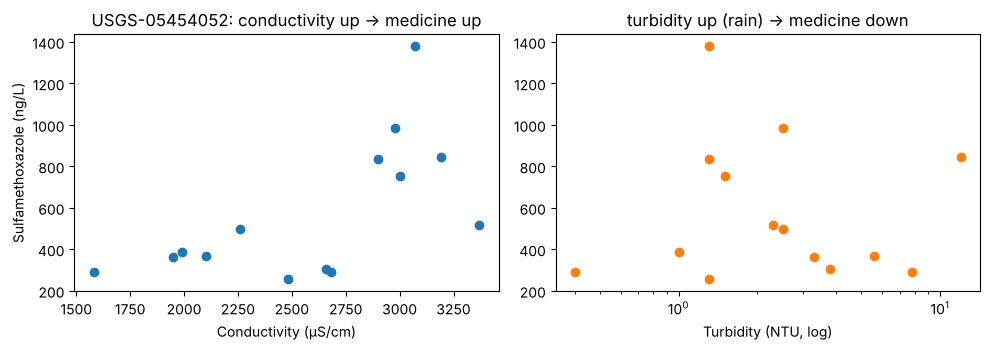

In [6]:
# picture: one well-sampled site for sulfamethoxazole
v='Sulfamethoxazole_ngL'; det=df[df[v].notna()]
best = det.groupby('site').apply(lambda g: g[['sc','turb']].notna().all(axis=1).sum()).idxmax()
g = det[det.site==best].dropna(subset=['sc','turb'])
fig, ax = plt.subplots(1,2, figsize=(10,3.6))
ax[0].scatter(g.sc, g[v]); ax[0].set_xlabel('Conductivity (µS/cm)'); ax[0].set_ylabel('Sulfamethoxazole (ng/L)'); ax[0].set_title(f'{best}: conductivity up → medicine up')
ax[1].scatter(g.turb, g[v], color='tab:orange'); ax[1].set_xscale('log'); ax[1].set_xlabel('Turbidity (NTU, log)'); ax[1].set_title('turbidity up (rain) → medicine down')
plt.tight_layout(); plt.show()

## Step 5: One model per medicine, tested on rivers it never saw (每种药一个模型)
- **Model:** gradient boosting (handles missing sensor values)
- **Test:** GroupKFold **by site**, so the model is always scored on rivers it never trained on
- **AUC:** 0.5 = coin flip, 1.0 = perfect
- **Hit rate:** if we sample only the **top 10% riskiest** readings, how often is the medicine really high? Compared with random sampling.

In [7]:
rows, imps = [], {}
for m,(d,T) in DATA.items():
    r = {'medicine': m, 'level T': round(T,1), 'above T': int(d.y.sum())}
    if d.y.sum() >= 40 and (len(d)-d.y.sum()) >= 40:
        F = [f for f in FEAT if d[f].notna().sum() >= 50 and d[f].nunique() > 5]
        clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, min_samples_leaf=40, random_state=0)
        p = cross_val_predict(clf, d[F].values, d.y.values, cv=GroupKFold(5), groups=d.site.values, method='predict_proba')[:,1]
        top = p >= np.quantile(p, .9)
        r.update({'AUC (new rivers)': round(roc_auc_score(d.y,p),3), 'hit rate top 10%': round(d.y.values[top].mean(),3), 'hit rate random': round(d.y.mean(),3)})
        r['times better'] = round(r['hit rate top 10%']/r['hit rate random'],1)
        clf.fit(d[F].values, d.y.values)
        pi = permutation_importance(clf, d[F].values, d.y.values, n_repeats=8, random_state=0, scoring='roc_auc')
        s = {}
        for f,val in zip(F, pi.importances_mean): s[FN[f]] = s.get(FN[f],0)+val
        imps[m] = s
    rows.append(r)
S = pd.DataFrame(rows).set_index('medicine'); S

,level T,above T,AUC (new rivers),hit rate top 10%,hit rate random,times better
medicine,,,,,,
Carbamazepine,11.9,890,0.823,0.363,0.068,5.3
Acetaminophen,42.0,398,0.742,0.135,0.032,4.2
Diclofenac,22.8,10,NaN,NaN,NaN,NaN
Atenolol,30.8,82,0.877,0.343,0.058,5.9
Ketoprofen,40.6,0,NaN,NaN,NaN,NaN
Sulfamethoxazole,38.4,669,0.846,0.605,0.160,3.8
Caffeine,100.0,1724,0.754,0.474,0.152,3.1


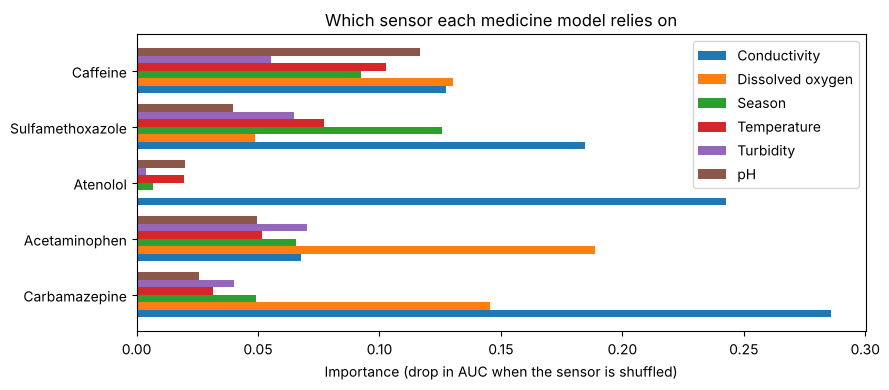

In [8]:
I = pd.DataFrame(imps).T.fillna(0)
I = I[['Conductivity','Dissolved oxygen','Season','Temperature','Turbidity','pH']]
ax = I.plot.barh(figsize=(9,4), width=0.8); ax.set_xlabel('Importance (drop in AUC when the sensor is shuffled)')
ax.set_title('Which sensor each medicine model relies on'); plt.tight_layout(); plt.show()

**Reading it:**
| Medicine | Model quality | Main sensors |
|---|---|---|
| Atenolol | AUC ≈ 0.88 | Conductivity (by far) |
| Sulfamethoxazole | AUC ≈ 0.85 | Conductivity, season |
| Carbamazepine | AUC ≈ 0.82 | Conductivity, then DO |
| Caffeine (sewage marker) | AUC ≈ 0.75 | DO, conductivity, pH |
| Paracetamol | AUC ≈ 0.74 | **DO** (breaks down fast, so it marks *fresh* sewage, which uses up oxygen) |
| Diclofenac, ketoprofen | not enough US detections | need Penang samples |

Flagging the top 10% riskiest readings finds high levels **3–6× more often than random sampling**. That is the **lab-cost saving (节省化验成本)** argument.

## Step 6: Harder test, whole states it never saw (换一个地区还准吗?)

In [9]:
def auc(d, F, grp):
    clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, min_samples_leaf=40, random_state=0)
    p = cross_val_predict(clf, d[F].values, d.y.values, cv=GroupKFold(5), groups=d[grp].values, method='predict_proba')[:,1]
    return round(roc_auc_score(d.y, p), 3)
rob = []
for m in ['Carbamazepine','Acetaminophen','Atenolol','Sulfamethoxazole','Caffeine']:
    d,_ = DATA[m]; d = d.copy(); d['state'] = d.state.fillna('NA').astype(str); d['org'] = d.org.fillna('NA')
    rob.append({'medicine': m, 'new rivers': auc(d,FEAT,'site'), 'new labs': auc(d,FEAT,'org'), 'new states': auc(d,FEAT,'state'),
                'conductivity only': auc(d,['log_sc'],'site')})
Rb = pd.DataFrame(rob).set_index('medicine'); Rb

,new rivers,new labs,new states,conductivity only
medicine,,,,
Carbamazepine,0.823,0.735,0.596,0.708
Acetaminophen,0.742,0.634,0.603,0.533
Atenolol,0.877,0.726,0.763,0.825
Sulfamethoxazole,0.846,0.542,0.554,0.656
Caffeine,0.754,0.650,0.588,0.520


**Reading it (very important):** accuracy **drops a lot in new states** (≈ 0.55–0.76). Each region has its own geology, salt levels and sewage mix.

👉 **For Penang:** a US-trained model **cannot** be used directly. What transfers is the **direction of the relationships** (conductivity ↑ and turbidity ↓ go with higher medicine levels). The numbers must be **re-learned from Penang samples**.

## Step 7: What this means for AquaTrace (对项目的意义)
1. **Conductivity is the #1 sensor** for sewage-borne medicines (atenolol, sulfamethoxazole, carbamazepine). **But Penang is tidal:** seawater raises conductivity far more than sewage does. So conductivity must be read **within a salinity zone** (river / estuary / coast). Phi's system already does this for its anomaly baseline.
2. **DO matters most for paracetamol and caffeine** (fresh sewage).
3. **Turbidity means different things for different medicines.** Rain dilutes treated-effluent medicines (carbamazepine, sulfamethoxazole), but can bring raw-sewage medicines (paracetamol, caffeine) through overflows. Penang's untreated drains behave like raw sewage, so paracetamol may rise with storm runoff there.
4. **Season / temperature matter** (warm water breaks medicines down). Penang has no winter, but monsoon vs dry season will play a similar role.
5. **UV254 and ORP** are too rare in public data to test here; that is a **research gap our boat can fill**.
6. **Diclofenac** is too rare in US rivers to model; Penang's much higher levels make local data essential.